# Task 2 — Supply-chain anomaly explainer (QLoRA fine-tune)

## Problem statement
**Input:** one incident record from a supply-chain control tower: event type, industry, severity, SKU, lane, dock, shift, expected vs observed quantity, dwell hours, optional temperature, optional 30-day supplier on-time rate, and an operator note. Records come in three formats (prose, JSON extract, shift log).

**Output:** a JSON object with `likely_cause`, `supporting_signals` (2–4), `immediate_action`, `escalation` (bool), `residual_risk`, `confidence` (0–1).

**Correct:** every signal is present in the record, the cause is consistent with the numbers, and the action is a concrete operational step (for example, quarantine the lot, or tender to the backup carrier).
**Incorrect:** contradicts the numbers (for example, calls a short delivery complete), invents metrics, parties, or costs, gives a generic action ("investigate further"), or is not valid JSON.

**Models:** teacher = Groq `openai/gpt-oss-120b` (data generation only). Student = `Qwen/Qwen2.5-3B-Instruct`

Secrets needed: `GROQ_API_KEY`, `HF_TOKEN` .

In [1]:
import os, subprocess
REPO_URL = "https://github.com/salukadev/CDAZZDEV-MLE-Saluka.git"  # public repo with task2_genai/data
if not os.path.exists("task2_genai"):
    if not os.path.exists("repo"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
    os.chdir("repo")
%pip install -q -r requirements-colab.txt
try:
    from google.colab import userdata
    for key in ("GROQ_API_KEY", "HF_TOKEN"):
        os.environ[key] = userdata.get(key)
except ImportError:
    from dotenv import load_dotenv; load_dotenv()
print("cwd:", os.getcwd(), "| keys set:", [k for k in ("GROQ_API_KEY", "HF_TOKEN") if os.environ.get(k)])

cwd: /content/repo | keys set: ['GROQ_API_KEY', 'HF_TOKEN']


## Dataset: teacher prompt, splits, and diversity

In [2]:
import json, re, collections
import pandas as pd, matplotlib.pyplot as plt
from task2_genai.src.diversity import diversity_report

DATA = "task2_genai/data"
read = lambda name: [json.loads(line) for line in open(f"{DATA}/{name}.jsonl")]
splits = {s: read(s) for s in ("train", "val", "test")}
meta = {s: read(f"{s}_meta") for s in splits}
total = sum(map(len, splits.values()))
print({s: f"{len(v)} ({len(v)/total:.0%})" for s, v in splits.items()}, "total", total)
print("\n--- Teacher system prompt (used only for data generation) ---\n")
print(open("task2_genai/prompts/teacher_system.txt").read())
print("--- Example chat record (Qwen chat format) ---")
print(json.dumps(splits["train"][0], indent=1)[:1500])

{'train': '120 (80%)', 'val': '15 (10%)', 'test': '15 (10%)'} total 150

--- Teacher system prompt (used only for data generation) ---

You are a senior supply-chain control-tower analyst writing gold labels for a fine-tuning dataset. You will be given one incident record. Return only a JSON object, with no markdown and no prose around it.

The JSON object must contain exactly these keys:
- likely_cause: string. Name one operational mechanism that the record supports. Do not merely repeat the event type.
- supporting_signals: array of 2 to 4 strings. Each string must cite a fact that appears in the record, including the number or condition when one was given.
- immediate_action: string. One specific next action a planner or warehouse lead can execute today. Name the object of the action (the SKU, lane, dock, carrier, or supplier) when the record provides it.
- escalation: boolean. True when the record shows a safety limit breach, a regulated product at risk, a customer line-down, a hos

{
 "count": 150,
 "prompt_length_chars": {
  "n": 150,
  "min": 424,
  "median": 727,
  "p90": 816,
  "max": 905
 },
 "event_type_max_share": 0.0667,
 "industry_counts": {
  "consumer_electronics": 26,
  "grocery_perishables": 26,
  "automotive_jit": 25,
  "apparel": 25,
  "pharma_cold_chain": 24,
  "industrial_parts": 24
 },
 "industry_max_share": 0.1733,
 "near_duplicates": {
  "threshold": 0.8,
  "near_duplicate_rate": 0.0,
  "flagged": 0,
  "max_nearest_jaccard": 0.7368,
  "median_nearest_jaccard": 0.6264
 }
}


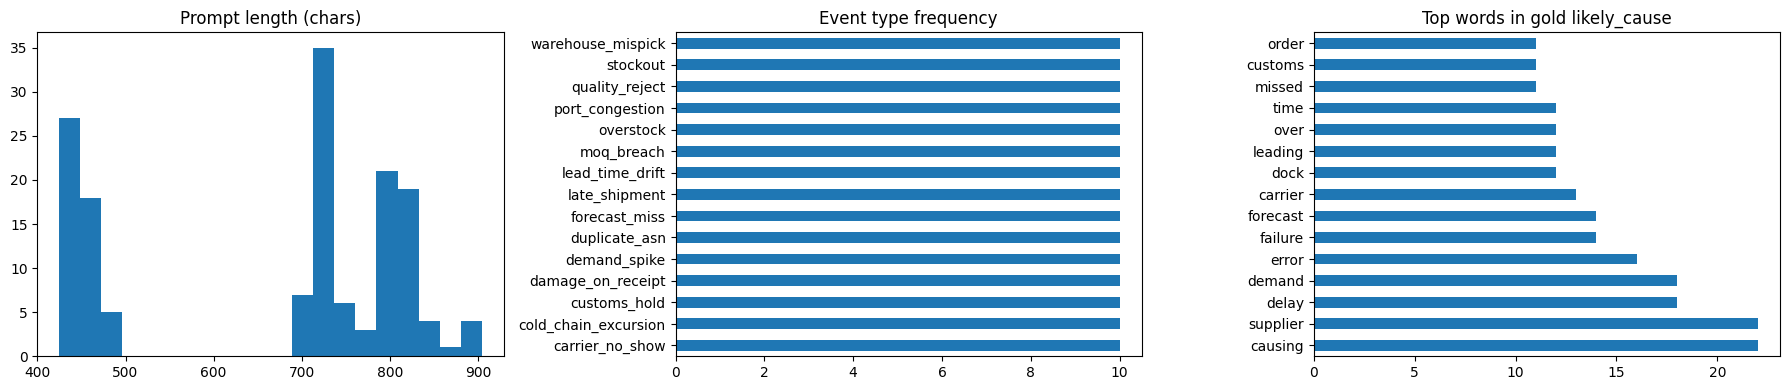

Top prompt keywords: [('json', 200), ('shift', 184), ('only', 165), ('lane', 159), ('dock', 156), ('severity', 150), ('expected', 150), ('hours', 150), ('context', 150), ('supplier', 130), ('quantity', 116), ('event', 105), ('note', 104), ('industry', 100), ('flag', 100), ('observed', 100), ('dwell', 100), ('explanation', 100), ('incident', 100), ('explain', 100), ('return', 100), ('temperature', 88), ('units', 78), ('time', 77), ('label', 74)]


In [3]:
records = [{"user_text": r["messages"][1]["content"], "event_type": m["event_type"], "industry": m["industry"]}
           for s in splits for r, m in zip(splits[s], meta[s])]
report = diversity_report(records)
print(json.dumps({k: v for k, v in report.items() if k != "event_type_counts"}, indent=1))

STOP = set("the a an and or of to in on for is are was it this that with at by be as from has have not no its into than if".split())
words = collections.Counter(w for r in records for w in re.findall(r"[a-z]{4,}", r["user_text"].lower()) if w not in STOP)
causes = collections.Counter(w for s in splits for r in splits[s]
                             for w in re.findall(r"[a-z]{4,}", json.loads(r["messages"][2]["content"])["likely_cause"].lower()) if w not in STOP)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist([len(r["user_text"]) for r in records], bins=20); ax[0].set_title("Prompt length (chars)")
pd.Series(report["event_type_counts"]).plot.barh(ax=ax[1], title="Event type frequency")
pd.Series(dict(causes.most_common(15))).plot.barh(ax=ax[2], title="Top words in gold likely_cause")
plt.tight_layout(); plt.show()
print("Top prompt keywords:", words.most_common(25))

## QLoRA hyperparameters (every value justified)

| Parameter | Value | Reason |
| --- | --- | --- |
| Quantization | 4-bit NF4, double quant | NF4 is the QLoRA data type for normally distributed weights. Double quant saves about 0.4 bits per parameter, so the 3B model fits on a 15 GB T4 with room for activations. |
| Compute dtype | bf16 on L4/A100, fp16 on T4 | The T4 has no bf16 support. Detected at runtime. |
| LoRA rank `r` | 16 | The task is a fixed 6-key schema plus domain wording, so the adapter needs little capacity. With 120 training rows, r=32 adds parameters without adding signal and raises overfitting risk. |
| LoRA alpha | 32 | alpha/r = 2 scales the adapter update so it is noticeable against the frozen weights at lr 2e-4, the common QLoRA ratio. |
| LoRA dropout | 0.05 | Light regularisation for a small dataset; higher values slow convergence across only 3 epochs. |
| Target modules | q,k,v,o + gate,up,down | Attention changes what the model attends to in the record. MLP layers carry the domain vocabulary (quarantine, tender, ASN). Adapting both is the QLoRA-paper setting. |
| Learning rate | 2e-4 | The standard rate for LoRA adapters. Full fine-tune rates (about 2e-5) barely move a rank-16 adapter in 45 steps. |
| Scheduler | cosine, warmup ratio 0.03 | A short warmup avoids an early spike on a fresh adapter. Cosine decay lowers the LR in the last epoch, which helps validation loss settle rather than oscillate. |
| Epochs | 3 | 120 rows / effective batch 8 = 15 steps per epoch, 45 in total: enough to lock in the JSON format. More epochs on 120 rows risk memorising, and the val loss below checks this. |
| Batch size / grad accumulation | 1 / 8 (effective 8) | Batch 1 keeps peak memory low on a T4. Accumulating 8 gives a less noisy gradient. |
| Max sequence length | 768 tokens | Longest prompt is about 1,000 chars (roughly 250 tokens). Add the system prompt (~150) and the JSON answer (~200), and an example is around 600 tokens, so 768 avoids truncation. 1024+ only raises the OOM risk. The token-length cell below verifies this. |
| Optimiser | paged_adamw_8bit | Paged 8-bit states avoid optimiser-memory spikes (QLoRA recommendation). |
| Eval / save | every epoch, keep best by eval_loss | Gives the required per-epoch train/val loss and restores the best checkpoint if val loss rises. |
| Seed | 42 | Reproducibility. |

In [4]:
import gc, torch
from datasets import Dataset
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from trl import SFTConfig, SFTTrainer
import trl.kernels.chunked_logprob as chunked_logprob
chunked_logprob._MM_OUT_DTYPE &= torch.cuda.get_device_capability()[0] >= 8

BF16 = torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if BF16 else torch.float16
print(torch.cuda.get_device_name(0), "| compute dtype:", DTYPE)
BNB = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
LORA = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])

def train(model_id, max_len):
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=BNB, device_map="auto", torch_dtype=DTYPE)
    model = get_peft_model(prepare_model_for_kbit_training(model), LORA)
    model.print_trainable_parameters()
    lengths = [len(tok.apply_chat_template(r["messages"], tokenize=True)) for r in splits["train"]]
    print(f"token lengths: max {max(lengths)}, mean {sum(lengths)/len(lengths):.0f} (max_length={max_len})")
    length_arg = "max_length" if "max_length" in SFTConfig.__dataclass_fields__ else "max_seq_length"
    args = SFTConfig(output_dir="outputs", num_train_epochs=3, per_device_train_batch_size=1, per_device_eval_batch_size=1,
                     gradient_accumulation_steps=8, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=1,
                     eval_strategy="epoch", logging_strategy="epoch", save_strategy="epoch", save_total_limit=1,
                     load_best_model_at_end=True, metric_for_best_model="eval_loss", optim="paged_adamw_8bit",
                     bf16=BF16, fp16=not BF16, report_to="none", seed=42, **{length_arg: max_len})
    trainer = SFTTrainer(model=model, args=args, processing_class=tok,
                         train_dataset=Dataset.from_list(splits["train"]), eval_dataset=Dataset.from_list(splits["val"]))
    trainer.train()
    return tok, model, trainer

# OOM handling: shorter sequences first, then the 1.5B model. Every failure is logged.
ATTEMPTS = [("Qwen/Qwen2.5-3B-Instruct", 768), ("Qwen/Qwen2.5-3B-Instruct", 512), ("Qwen/Qwen2.5-1.5B-Instruct", 512)]
OOM_LOG = []
for MODEL_ID, MAX_LEN in ATTEMPTS:
    try:
        tok, model, trainer = train(MODEL_ID, MAX_LEN)
        break
    except torch.cuda.OutOfMemoryError as exc:
        OOM_LOG.append({"model": MODEL_ID, "max_length": MAX_LEN, "error": str(exc)[:200]})
        print("OOM ->", OOM_LOG[-1])
        gc.collect(); torch.cuda.empty_cache()
print("Trained:", MODEL_ID, "max_length", MAX_LEN, "| OOM log:", OOM_LOG or "no OOM encountered")

Tesla T4 | compute dtype: torch.bfloat16


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607
token lengths: max 2, mean 2 (max_length=768)


Tokenizing train dataset:   0%|          | 0/120 [00:00<?, ? examples/s]

...

Building labels for eval dataset:   0%|          | 0/15 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/15 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/15 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,2.100222,1.092181,1.178329,0.767116,58866.000000
2,0.808141,0.692984,0.702491,0.839742,117732.000000
3,0.600719,0.649674,0.601100,0.847146,176598.000000


Trained: Qwen/Qwen2.5-3B-Instruct max_length 768 | OOM log: no OOM encountered


In [5]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))
!nvidia-smi

True Tesla T4
Wed Oct 14 08:05:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             46W /   70W |    3993MiB /  15360MiB |      5%      Default |
|                                         |                        |                  N/A |
+---------------------------------

 epoch  train_loss  val_loss
     1    2.100222  1.092181
     2    0.808141  0.692984
     3    0.600719  0.649674
Validation loss decreases every epoch: True


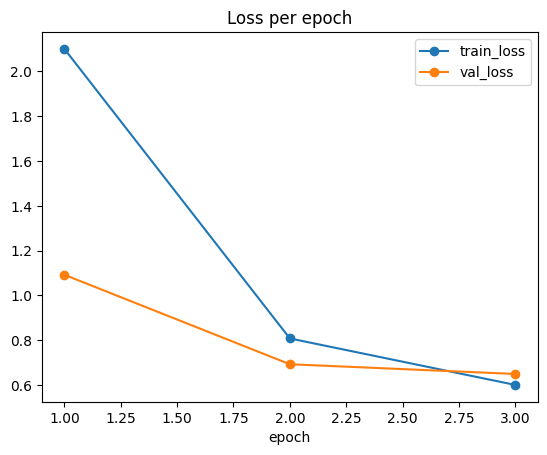

In [6]:
hist = trainer.state.log_history
train_loss = [h["loss"] for h in hist if "loss" in h]
val_loss = [h["eval_loss"] for h in hist if "eval_loss" in h]
loss_df = pd.DataFrame({"epoch": range(1, len(val_loss) + 1), "train_loss": train_loss[: len(val_loss)], "val_loss": val_loss})
print(loss_df.to_string(index=False))
print("Validation loss decreases every epoch:", all(b < a for a, b in zip(val_loss, val_loss[1:])))
loss_df.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", title="Loss per epoch"); plt.show()

## Evaluation on the held-out test set
The base model is the same 4-bit Qwen with adapters **disabled** and the same system prompt. The fine-tuned model has adapters enabled. Both use greedy decoding on identical test rows.

In [7]:
from task2_genai.src.schemas import AnomalyExplanation
from task2_genai.src.generate_dataset import extract_json
from task2_genai.src.evaluate import mean_rouge_l

def generate(messages, max_new_tokens=320):
    prompt = tok.apply_chat_template(messages[:2], tokenize=False, add_generation_prompt=True)
    ids = tok(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def valid(text):
    try: AnomalyExplanation.model_validate(extract_json(text)); return True
    except Exception: return False

model.eval(); model.config.use_cache = True
test = splits["test"]
gold = [r["messages"][2]["content"] for r in test]
with model.disable_adapter():
    base_preds = [generate(r["messages"]) for r in test]
tuned_preds = [generate(r["messages"]) for r in test]

results = pd.DataFrame({
    "model": ["Base Qwen + system prompt", "Fine-tuned (QLoRA)"],
    "ROUGE-L F1": [mean_rouge_l(base_preds, gold), mean_rouge_l(tuned_preds, gold)],
    "valid schema JSON": [sum(map(valid, base_preds)) / len(test), sum(map(valid, tuned_preds)) / len(test)],
    "test rows": [len(test)] * 2,
})
results

,model,ROUGE-L F1,valid schema JSON,test rows
0,Base Qwen + system prompt,0.375099,0.666667,15
1,Fine-tuned (QLoRA),0.499289,1.000000,15


### Additional metric — LLM-as-judge (Groq `openai/gpt-oss-120b`, Pydantic-validated JSON)
The rubric is in `task2_genai/prompts/judge_system.txt`. It scores faithfulness (1–5), specificity (1–5), and a hallucinated flag. Invalid judge JSON is logged and retried once.

In [8]:
import time
from groq import Groq
from task2_genai.src.evaluate import judge_one

client = Groq()
judged = {"base": [], "tuned": []}
for i, row in enumerate(test):
    for name, preds in (("base", base_preds), ("tuned", tuned_preds)):
        judged[name].append(judge_one(client, os.environ.get("GROQ_MODEL", "openai/gpt-oss-120b"), row["messages"][1]["content"], gold[i], preds[i]))
        time.sleep(2)  # stay under the Groq free-tier rate limit

def summarise(scores):
    ok = [s for s in scores if s]
    return {"faithfulness": sum(s.faithfulness for s in ok) / len(ok), "specificity": sum(s.specificity for s in ok) / len(ok),
            "judge_hallucination_rate": sum(s.hallucinated for s in ok) / len(ok), "judged": f"{len(ok)}/{len(scores)}"}
pd.DataFrame({"Base": summarise(judged["base"]), "Fine-tuned": summarise(judged["tuned"])}).T

,faithfulness,specificity,judge_hallucination_rate,judged
Base,3.266667,3.4,0.533333,15/15
Fine-tuned,3.6,4.533333,0.666667,15/15


### Manual review — 10 fine-tuned responses
Read each response against its incident. Then set `REVIEW_LABELS` to `correct`, `partially_correct`, or `hallucinated`. The judge's flag is shown only as a hint.

In [9]:
for i in range(10):
    print(f"===== #{i} =====\nINCIDENT:\n{test[i]['messages'][1]['content'][:700]}\n")
    print(f"FINE-TUNED:\n{tuned_preds[i]}\n\nGOLD:\n{gold[i]}")
    j = judged["tuned"][i]
    print(f"judge hint: hallucinated={j.hallucinated if j else 'n/a'} ({j.brief_reason if j else ''})\n")

===== #0 =====
INCIDENT:
Please explain incident INC-7-0059. SKU AUT-CARR-1059 moves on lane MUN-LAX in automotive jit. The event label is carrier no show and the severity flag is medium. We expected 243 units and the floor counted 0. It has dwelled 7.8 hours at dock D30 during the afternoons shift. Temperature was not recorded. No 30-day on-time rate is available. Context: an engine-plant line that stops if this part is missing at the next shift change. The booked carrier did not collect during the tender window. The trailer is loaded and sealed but still at the shipper dock. The receiving site is waiting for a revised ETA. The carrier scorecard should record this missed collection. Backup capacity on this lane has

FINE-TUNED:
{"likely_cause": "carrier scheduling error", "supporting_signals": ["Event label is carrier no show", "Carrier did not collect during the tender window", "Trailer is loaded and sealed but still at the shipper dock"], "immediate_action": "Contact the carrier to 

In [15]:
from task2_genai.src.evaluate import hallucination_rate

REVIEW_LABELS = ["partially_correct", "hallucinated", "hallucinated", "hallucinated", "partially_correct",
                 "correct", "hallucinated", "correct", "partially_correct", "correct"]
if all(REVIEW_LABELS):
    print(pd.Series(REVIEW_LABELS).value_counts().to_string())
    print(f"Hallucination rate: {hallucination_rate(REVIEW_LABELS):.0%} of {len(REVIEW_LABELS)} reviewed responses")

hallucinated         4
partially_correct    3
correct              3
Hallucination rate: 40% of 10 reviewed responses


### Qualitative analysis

**Where fine-tuning helped.** Schema-valid JSON rose from 10/15 to 15/15, ROUGE-L from 0.375 to 0.499, and judge specificity from 3.40 to 4.53. Actions became concrete and record-grounded, e.g. #5 cancels the duplicate ASN in the WMS and #7 notes there is no shortage yet (760/760) and asks the carrier for the tractor number.

**Remaining failure modes.** 4/10 reviewed answers were hallucinated (40%), mostly quantity slips (#3, #6, #8) plus one reversed negation (#2), and confidence never drops below 0.85, so the RAG fallback never fires. Next steps: put derived numbers (shortage = expected - observed) in the input, add training examples with negations and available alternatives, use more judge-filtered data, and calibrate confidence.

## Additional — RAG fallback when self-rated confidence is low
SOP snippets (`task2_genai/sop_corpus/sops.jsonl`) are embedded into an in-memory ChromaDB collection. If the model's `confidence` is below 0.6 (or missing), the top SOP is retrieved and the model is re-queried with it.

In [11]:
import chromadb
from task2_genai.src.evaluate import parse_confidence

sops = [json.loads(line) for line in open("task2_genai/sop_corpus/sops.jsonl")]
collection = chromadb.Client().get_or_create_collection("sops")
collection.add(ids=[s["doc_id"] for s in sops], documents=[s["text"] for s in sops])
THRESHOLD = 0.6

confs = [parse_confidence(p) for p in tuned_preds]
i = min(range(len(test)), key=lambda k: -1 if confs[k] is None else confs[k])
row, before = test[i], tuned_preds[i]
print(f"Lowest-confidence test row #{i}: confidence={confs[i]} (threshold {THRESHOLD}) -> fallback {'TRIGGERED' if confs[i] is None or confs[i] < THRESHOLD else 'not needed; shown for illustration'}")
sop = collection.query(query_texts=[row["messages"][1]["content"]], n_results=1)["documents"][0][0]
after = generate([row["messages"][0], {"role": "user", "content": row["messages"][1]["content"] + "\n\nRelevant SOP:\n" + sop}])
print("\nRETRIEVED SOP:", sop, "\n\nBEFORE:", before, "\n\nAFTER:", after)
print(f"\nROUGE-L vs gold: before {mean_rouge_l([before], [gold[i]]):.3f} -> after {mean_rouge_l([after], [gold[i]]):.3f}; confidence after: {parse_confidence(after)}")

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:06<00:00, 13.3MiB/s]


Lowest-confidence test row #0: confidence=0.85 (threshold 0.6) -> fallback not needed; shown for illustration

RETRIEVED SOP: Carrier no-show SOP. If the booked truck did not collect, tender the load to the backup carrier on the lane card and notify the receiving site of the new ETA. Record the miss against the carrier scorecard. 

BEFORE: {"likely_cause": "carrier scheduling error", "supporting_signals": ["Event label is carrier no show", "Carrier did not collect during the tender window", "Trailer is loaded and sealed but still at the shipper dock"], "immediate_action": "Contact the carrier to confirm a new pickup date and request a revised ETA for SKU AUT-CARR-1059", "escalation": true, "residual_risk": "If the carrier fails to deliver the shipment on the revised ETA, the engine-plant line may still stop due to the missing part", "confidence": 0.85} 

AFTER: {"likely_cause": "carrier failure to collect", "supporting_signals": ["Event label is carrier no show", "Expected 243 units bu

## Merge adapters and push the merged model to Hugging Face

In [13]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
import os, json, torch
os.chdir("/content/repo")
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
from huggingface_hub import whoami

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="auto")
merged = PeftModel.from_pretrained(base, "adapters").merge_and_unload()
merged.save_pretrained("merged_model"); tok.save_pretrained("merged_model")

HF_REPO_ID = f"{whoami(token=os.environ['HF_TOKEN'])['name']}/supply-chain-anomaly-{MODEL_ID.split('/')[-1].lower()}"
merged.push_to_hub(HF_REPO_ID, token=os.environ["HF_TOKEN"], private=False)
tok.push_to_hub(HF_REPO_ID, token=os.environ["HF_TOKEN"], private=False)
print("Merged model:", f"https://huggingface.co/{HF_REPO_ID}")

# smoke test: the merged model answers one test incident
row = json.loads(open("task2_genai/data/test.jsonl").readline())
prompt = tok.apply_chat_template(row["messages"][:2], tokenize=False, add_generation_prompt=True)
ids = tok(prompt, return_tensors="pt").to(merged.device)
out = merged.generate(**ids, max_new_tokens=320, do_sample=False, pad_token_id=tok.eos_token_id)
print(tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpt56qfxv0/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

Merged model: https://huggingface.co/paulg28/supply-chain-anomaly-qwen2.5-3b-instruct
{"likely_cause": "carrier no-show causing shipment delay", "supporting_signals": ["Expected 243 units but floor counted 0", "Trailer is loaded and sealed but still at the shipper dock", "DWELLING time of 7.8 hours indicates prolonged hold", "No GPS ping exists because the freight never left"], "immediate_action": "Contact the carrier to confirm the revised ETA and request a new tender for the shipment", "escalation": true, "residual_risk": "If the revised ETA remains delayed, the engine-plant line may still stop due to the missing part, risking production downtime", "confidence": 0.85}


In [ ]:
# from huggingface_hub import whoami
# from peft import PeftModel

# trainer.save_model("adapters")  # best checkpoint (load_best_model_at_end)
# del model, trainer; gc.collect(); torch.cuda.empty_cache()
# base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="auto")
# merged = PeftModel.from_pretrained(base, "adapters").merge_and_unload()
# merged.save_pretrained("merged_model"); tok.save_pretrained("merged_model")

# HF_REPO_ID = f"{whoami(token=os.environ['HF_TOKEN'])['name']}/supply-chain-anomaly-{MODEL_ID.split('/')[-1].lower()}"
# merged.push_to_hub(HF_REPO_ID, token=os.environ["HF_TOKEN"], private=False)
# tok.push_to_hub(HF_REPO_ID, token=os.environ["HF_TOKEN"], private=False)
# print("Merged model:", f"https://huggingface.co/{HF_REPO_ID}")

# model = merged  # smoke test: the merged model answers one test incident
# print(generate(test[0]["messages"]))